### A. yfinance — Market Data Retrieval

**Purpose**

`yfinance` is a Python library that provides a convenient interface for downloading financial market data from Yahoo Finance. It is going to be useful when it comes to looking at stock prices and building the market-data portion of our backtesting system.

**Potential use cases**

* Retrieve historical open, high, low, close, and volume data.
* Examine adjusted prices, dividends, and stock splits.
* Build market features and calculate historical returns.
* Prototype and test trading strategies in a Jupyter Notebook.

**Advantages**

* Simple Python interface that integrates with pandas.
* Easy to understand and make adjsutments.
* Quick to prototype without manually constructing API requests.
* Useful for exploratory analysis and initial backtesting experiments.

**Disadvantages and limitations**
* It is an unofficial interface to Yahoo Finance, not an official Yahoo Finance market-data API contract.
* Availability, behavior, or data fields may change.
* Historical prices downloaded today do not automatically establish what price data was available at a particular historical time.
* Adjusted prices can incorporate corporate actions that occurred later, so the chosen price field and adjustment methodology must be documented.
* Downloaded data should be validated and cached rather than assumed to be permanently reproducible.

**Relevance to Quant Time Machine**

We should be using `yfinance` as way to test initial market-data experiments. Before we start building anything to do with point in type testing we need to investigate whether the data supports the historical availability and investement strategy testing to use. We also can not assume that downloading historical data will eliminate look-ahead bias.


In [9]:
%pip install yfinance pandas matplotlib
## need to run this to be able to use yfinance

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [10]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# Example: download daily data for Apple
ticker = yf.Ticker("AAPL")

prices = ticker.history(
    start="2023-01-01", #Start date 
    end="2025-01-01", 
    interval="1d",
    auto_adjust=False
)

display(prices.head())

,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
Date,,,,,,,,
2023-01-03 00:00:00-05:00,130.279999,130.899994,124.169998,125.070000,122.876747,112117500,0.0,0.0
2023-01-04 00:00:00-05:00,126.889999,128.660004,125.080002,126.360001,124.144119,89113600,0.0,0.0
2023-01-05 00:00:00-05:00,127.129997,127.769997,124.760002,125.019997,122.827599,80962700,0.0,0.0
2023-01-06 00:00:00-05:00,126.010002,130.289993,124.889999,129.619995,127.346962,87754700,0.0,0.0
2023-01-09 00:00:00-05:00,130.470001,133.410004,129.889999,130.149994,127.867645,70790800,0.0,0.0


In [11]:
#Print statements to better understand the data

print("Rows and columns:", prices.shape)
print("\nColumns:")
print(prices.columns.tolist())

print("\nMissing values:")
print(prices.isna().sum())

print("\nDate range:")
print(prices.index.min(), "to", prices.index.max())

Rows and columns: (502, 8)

Columns:
['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits']

Missing values:
Open            0
High            0
Low             0
Close           0
Adj Close       0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64

Date range:
2023-01-03 00:00:00-05:00 to 2024-12-31 00:00:00-05:00


,Adj Close,Daily_Return
Date,,
2024-12-24 00:00:00-05:00,256.339752,0.011478
2024-12-26 00:00:00-05:00,257.153809,0.003176
2024-12-27 00:00:00-05:00,253.748550,-0.013242
2024-12-30 00:00:00-05:00,250.382965,-0.013263
2024-12-31 00:00:00-05:00,248.615814,-0.007058


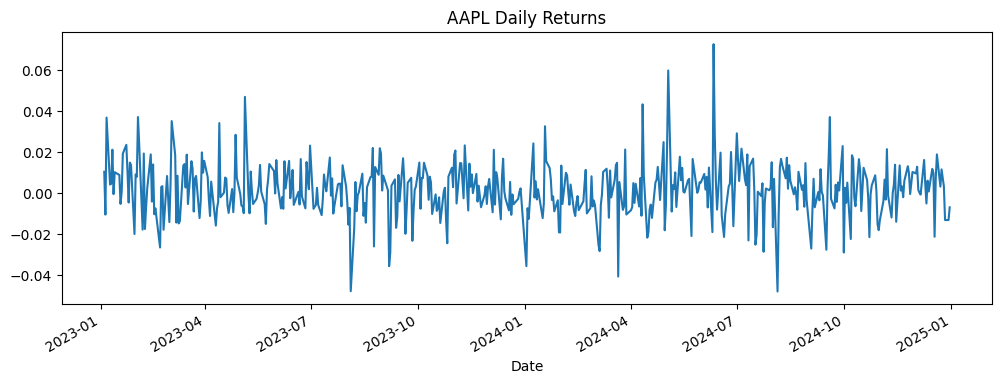

In [12]:
# Use adjusted closing prices for this example.
# Document the adjustment methodology in any actual backtest.
prices["Daily_Return"] = prices["Adj Close"].pct_change()

display(prices[["Adj Close", "Daily_Return"]].tail())

prices["Daily_Return"].plot(
    title="AAPL Daily Returns",
    figsize=(12, 4)
)
plt.show()

# FRED API — Economic Data Retrieval

### Purpose

FRED (Federal Reserve Economic Data), maintained by the Federal Reserve Bank of St. Louis, provides access to economic time series through an official API.

Examples include:

* Consumer Price Index (CPI) and inflation-related measures.
* Unemployment rates.
* Treasury yields and interest rates.
* GDP and other macroeconomic indicators.

**Advantages**

Provides structured economic time-series data.
Supports metadata and observation queries.
Allows filtering by observation dates and requesting different data frequencies.
Supports real-time-period parameters that help distinguish historical data from what is available today.

**Disadvantages and limitations**

* Economic data may be released after its observation date and revised afterward.
* Requesting a historical observation period does not necessarily retrieve the value known at that historical time.
* Indicators have different frequencies and release schedules, requiring careful alignment with market data.
* The API does not automatically prevent look-ahead bias in a backtest.
* C. ALFRED — Historical Economic Data Vintages

# ALFRED (Archival Federal Reserve Economic Data) preserves historical versions of economic series so researchers can examine what was reported at different points in time.

For example, an initial GDP estimate may later be revised. A backtest performed using today's revised value could use information that was not available when the original estimate was published.

**Advantages**

Helps reconstruct historical economic-data vintages.
Supports research into revisions and historical forecasting.
Is particularly useful for avoiding look-ahead bias caused by revised macroeconomic data.

**Disadvantages and limitations**

Requires understanding vintage dates and the distinction between observation dates and publication dates.
A vintage date alone may not precisely represent the time a release became available to a trading strategy.
Coverage and revision histories depend on the series.
The backtesting system must still enforce when each release became usable.

Relevance to Quant Time Machine

FRED is a convenient source for current historical economic series, while ALFRED is especially valuable when a strategy must use the economic-data versions that existed in the past. Both should be incorporated through a data layer that tracks observation dates, release availability, vintage dates, and source metadata.

Jeudy, E. (2026). Finance Fundamentals for Computer Science Students: A Learning Roadmap for Quant Time Machine. ChatGPT (GPT-6), OpenAI. Conversation dated October 5, 2026.

In [13]:
%pip install fredapi pandas matplotlib

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [15]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from fredapi import Fred

api_key = "5074066df2ddcf9f865a8ed5b72e1e63" #Elijah.Jeudy10 API key

fred = Fred(api_key=api_key)

if not api_key:
    raise ValueError(
        "Set the FRED_API_KEY environment variable first."
    )

fred = Fred(api_key=api_key)

In [16]:
unemployment = fred.get_series(
    "UNRATE",
    observation_start="2018-01-01",
    observation_end="2024-12-31"
)

unemployment = unemployment.rename("Unemployment_Rate")

display(unemployment.head())
display(unemployment.tail())

2018-01-01    4.0
2018-02-01    4.1
2018-03-01    4.0
2018-04-01    4.0
2018-05-01    3.8
Name: Unemployment_Rate, dtype: float64

2024-08-01    4.2
2024-09-01    4.1
2024-10-01    4.1
2024-11-01    4.2
2024-12-01    4.1
Name: Unemployment_Rate, dtype: float64

In [17]:
vintage_date = "2020-06-01"

unemployment_vintage = fred.get_series(
    "UNRATE",
    observation_start="2018-01-01",
    observation_end="2020-06-01",
    vintage_date=vintage_date
)

display(unemployment_vintage.tail(10))

2019-09-01     3.5
2019-10-01     3.6
2019-11-01     3.6
2019-12-01     3.6
2020-01-01     3.6
2020-02-01     3.5
2020-03-01     4.4
2020-04-01    14.8
2020-05-01    13.2
2020-06-01    11.0
dtype: float64

### Conclusion

For our initial Quant Time Machine prototype, we recommend evaluating `yfinance` for market-price retrieval and FRED/ALFRED for economic indicators and historical economic-data,

`yfinance` offers a simple way to experiment with market data, but its unofficial interface and historical-data limitations require testing before we can use it . FRED provides structured economic time series, while ALFRED adds important historical-vintage capabilities for research that must avoid look-ahead bias from revised economic data which our time machine is looking for.

Neither source alone solves the full point-in-time problem. Our architecture should preserve source metadata and retrieval records, model when information actually became available, and expose only eligible data to the backtesting engine.

The next step in investigating is seeing which of these API can help manage data the best

More API's to investigate 1. 
SEC EDGAR API,  Alpha Vantage, Nasdap Data Link